In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os
os.chdir("/content/drive/MyDrive/q2")
print(os.getcwd(), os.listdir()) 

/content/drive/.shortcut-targets-by-id/1OxriQOhkBTmc305lsDmCm_jfz6fiu2Rp/q2 ['student_train.csv', 'optional_external_data.csv', 'student_test.csv', 'results', '__pycache__', 'autoformer.py']


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pathlib import Path

RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

def save(fig, name):
    fig.savefig(RESULTS / f"{name}.pdf", bbox_inches="tight")

device: cuda


In [6]:
train = pd.read_csv("/content/drive/MyDrive/q2/student_train.csv")
test  = pd.read_csv("/content/drive/MyDrive/q2/student_test.csv")
ext   = pd.read_csv("/content/drive/MyDrive/q2/optional_external_data.csv")

assert train.time_idx.tolist() == list(range(1, len(train) + 1))  
assert len(test) == 168 and test.time_idx.iloc[0] == train.time_idx.iloc[-1] + 1
assert ext.time_idx.tolist() == list(range(1, len(ext) + 1))   
assert len(ext) == len(train) + len(test)
assert train.value.isna().sum() == 0 and (train.value >= 0).all()

y = train.value.to_numpy(dtype=float)
print(f"train {len(y)} | test {len(test)} ({test.time_idx.min()}–{test.time_idx.max()}) | ext {len(ext)}")
print(train.value.describe().round(1))
print("quantiles:", train.value.quantile([0.5, 0.9, 0.99, 0.999]).round(0).to_dict())

train 43656 | test 168 (43657–43824) | ext 43824
count    43656.0
mean        98.2
std         90.8
min          0.0
25%         30.0
50%         73.0
75%        136.0
max        994.0
Name: value, dtype: float64
quantiles: {0.5: 73.0, 0.9: 218.0, 0.99: 418.0, 0.999: 571.0}


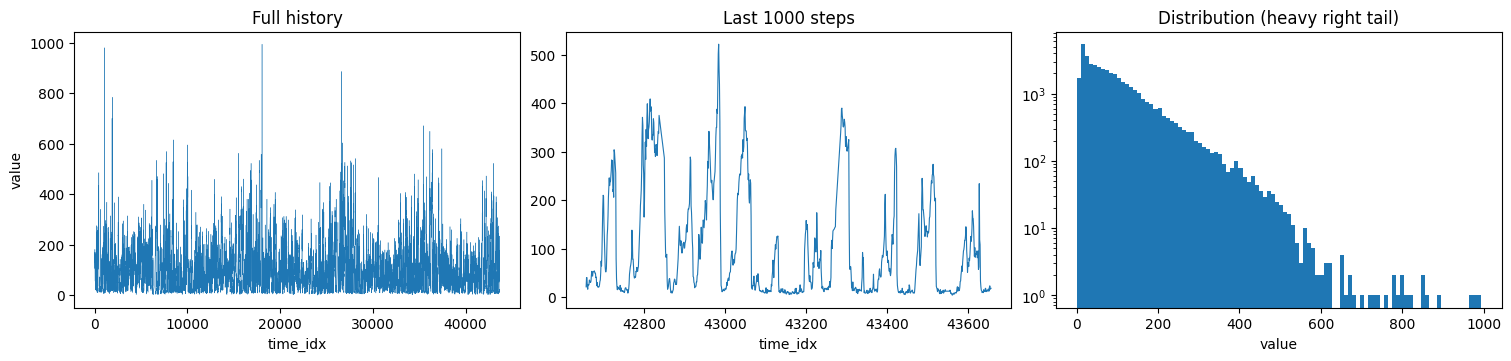

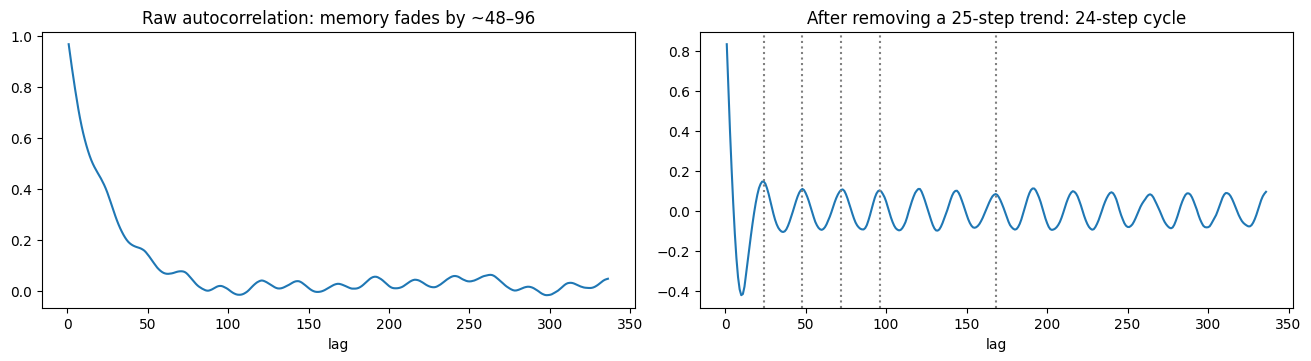

raw ACF: {1: np.float64(0.966), 6: np.float64(0.749), 12: np.float64(0.57), 24: np.float64(0.402), 48: np.float64(0.158), 96: np.float64(0.019), 168: np.float64(0.028)}
residual ACF: {12: np.float64(-0.378), 24: np.float64(0.146), 36: np.float64(-0.105), 48: np.float64(0.11), 72: np.float64(0.105), 168: np.float64(0.084)}


In [7]:
def acf(x, lags):
    x = x - x.mean()
    return np.array([np.corrcoef(x[:-k], x[k:])[0, 1] for k in lags])

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), layout="constrained")
ax[0].plot(train.time_idx, y, lw=0.3); ax[0].set(title="Full history", xlabel="time_idx", ylabel="value")
ax[1].plot(train.time_idx[-1000:], y[-1000:], lw=0.8); ax[1].set(title="Last 1000 steps", xlabel="time_idx")
ax[2].hist(y, bins=100); ax[2].set(title="Distribution (heavy right tail)", xlabel="value", yscale="log")
save(fig, "A1_overview"); plt.show()

lags = np.arange(1, 337)
trend = pd.Series(y).rolling(25, center=True, min_periods=1).mean().to_numpy()
acf_raw, acf_res = acf(y, lags), acf(y - trend, lags)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5), layout="constrained")
ax[0].plot(lags, acf_raw); ax[0].set(title="Raw autocorrelation: memory fades by ~48–96", xlabel="lag")
ax[1].plot(lags, acf_res)
for m in (24, 48, 72, 96, 168): ax[1].axvline(m, ls=":", c="gray")
ax[1].set(title="After removing a 25-step trend: 24-step cycle", xlabel="lag")
save(fig, "A2_autocorrelation"); plt.show()

print("raw ACF:", {k: round(acf_raw[k - 1], 3) for k in (1, 6, 12, 24, 48, 96, 168)})
print("residual ACF:", {k: round(acf_res[k - 1], 3) for k in (12, 24, 36, 48, 72, 168)})

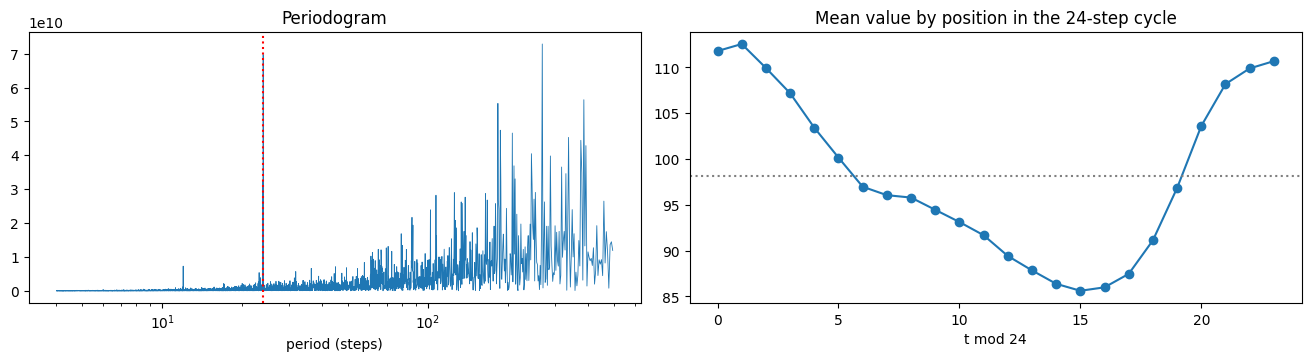

strongest periods: [269.5  24.  386.3 183.4 187.4 207.9]
24-step profile range 86–113 vs overall std 91


In [8]:
x = y - y.mean()
freq = np.fft.rfftfreq(len(x)); power = np.abs(np.fft.rfft(x)) ** 2
keep = (freq > 1 / 500) & (freq < 1 / 4)
period = 1 / freq[keep]

profile24 = pd.Series(y).groupby(np.arange(len(y)) % 24).mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5), layout="constrained")
ax[0].plot(period, power[keep], lw=0.6); ax[0].set(xscale="log", title="Periodogram", xlabel="period (steps)")
ax[0].axvline(24, ls=":", c="r")
ax[1].plot(profile24.index, profile24.values, marker="o")
ax[1].axhline(y.mean(), ls=":", c="gray")
ax[1].set(title="Mean value by position in the 24-step cycle", xlabel="t mod 24")
save(fig, "A3_spectrum_profile"); plt.show()

top = np.argsort(power[keep])[::-1][:6]
print("strongest periods:", np.round(period[top], 1))
print(f"24-step profile range {profile24.min():.0f}–{profile24.max():.0f} vs overall std {y.std():.0f}")

In [9]:
cat_cols = ["feature_G", "feature_H", "feature_I", "feature_J"]
assert (ext[cat_cols].sum(axis=1) == 1).all()            
category = ext[cat_cols].to_numpy().argmax(axis=1)
changed = np.r_[False, category[1:] != category[:-1]]

for c in ["feature_D", "feature_E", "feature_F"]:         
    drops = np.r_[False, np.diff(ext[c].to_numpy()) < 0]
    print(f"{c}: zero {np.mean(ext[c] == 0):.1%} | drops {drops.sum()} | "
          f"drops at a category change {changed[drops].mean():.1%}")

merged = ext.merge(train, on="time_idx")
target = merged.value.to_numpy(dtype=float)
rows = []
for c in [f"feature_{k}" for k in "ABCDEFGHIJ"]:
    f = merged[c].to_numpy(dtype=float)
    row = {"feature": c, "same time": np.corrcoef(f, target)[0, 1]}
    for h in (24, 96, 168):                               
        row[f"target +{h}"] = np.corrcoef(f[:-h], target[h:])[0, 1]
    rows.append(row)
table_a4 = pd.DataFrame(rows).round(3)
table_a4.to_csv(RESULTS / "A4_feature_correlations.csv", index=False)
table_a4

feature_D: zero 0.0% | drops 8283 | drops at a category change 100.0%
feature_E: zero 99.2% | drops 66 | drops at a category change 42.4%
feature_F: zero 95.9% | drops 544 | drops at a category change 46.9%


,feature,same time,target +24,target +96,target +168
0,feature_A,0.169,0.024,-0.090,-0.073
1,feature_B,-0.088,-0.106,-0.122,-0.116
2,feature_C,-0.048,0.089,0.129,0.091
3,feature_D,-0.245,-0.148,0.008,-0.008
4,feature_E,0.019,-0.006,-0.008,0.036
5,feature_F,-0.050,-0.059,-0.029,-0.027
6,feature_G,-0.033,-0.019,0.004,-0.002
7,feature_H,-0.212,-0.171,0.029,0.023
8,feature_I,0.097,0.086,-0.038,-0.025
9,feature_J,0.154,0.110,0.007,0.005


### Validation design and baselines

train [0, 38280) | validation [38280, 40968) | holdout [40968, 43656) | origins: val 106, holdout 106


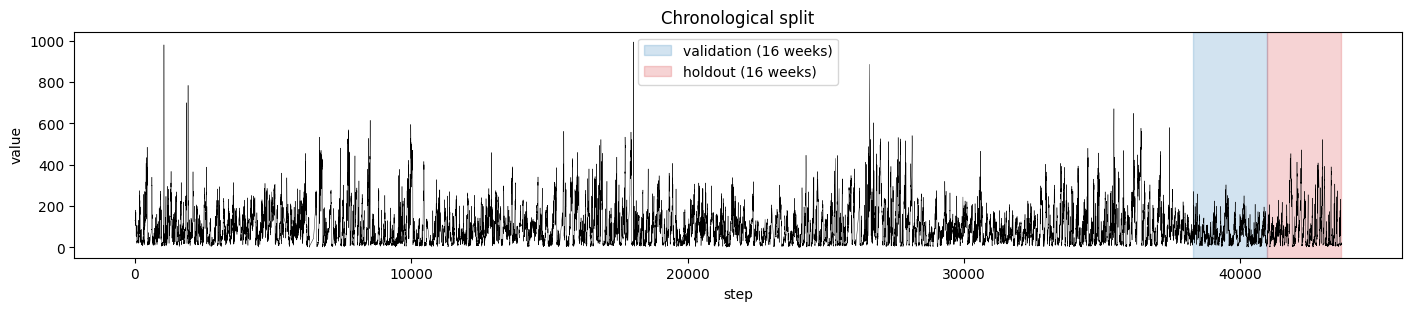

In [10]:
# The split and forecast origins

H = 168                       
BLOCK = 16 * H                   # 16 weeks of 168 steps
N = len(y)
HOLDOUT_START = N - BLOCK        
VAL_START = HOLDOUT_START - BLOCK

def make_origins(start, end, stride=24, context=0):
    """Forecast origins o whose whole target y[o:o+H] lies in [start, end)."""
    return np.arange(max(start, context), end - H + 1, stride)

def targets(origins):
    return np.stack([y[o:o + H] for o in origins])

VAL_ORIGINS = make_origins(VAL_START, HOLDOUT_START)
HOLD_ORIGINS = make_origins(HOLDOUT_START, N)
Y_val = targets(VAL_ORIGINS)
print(f"train [0, {VAL_START}) | validation [{VAL_START}, {HOLDOUT_START}) "
      f"| holdout [{HOLDOUT_START}, {N}) | origins: val {len(VAL_ORIGINS)}, holdout {len(HOLD_ORIGINS)}")

fig, ax = plt.subplots(figsize=(14, 3), layout="constrained")
ax.plot(np.arange(N), y, lw=0.3, c="k")
ax.axvspan(VAL_START, HOLDOUT_START, color="tab:blue", alpha=0.2, label="validation (16 weeks)")
ax.axvspan(HOLDOUT_START, N, color="tab:red", alpha=0.2, label="holdout (16 weeks)")
ax.set(title="Chronological split", xlabel="step", ylabel="value"); ax.legend()
save(fig, "B1_split"); plt.show()

In [11]:
# Metrics

def metrics(pred, true):
    err = pred - true
    denom = np.abs(true) + np.abs(pred)
    smape = np.where(denom > 0, 2 * np.abs(err) / np.where(denom > 0, denom, 1), 0.0)  # 0/0 counts as 0
    return {"RMSE": float(np.sqrt(np.mean(err ** 2))),
            "MAE": float(np.mean(np.abs(err))),
            "sMAPE": float(100 * np.mean(smape))}

def horizon_rmse(pred, true):   # one RMSE per horizon step 1..168
    return np.sqrt(np.mean((pred - true) ** 2, axis=0))

def block_rmse(pred, true):     # one RMSE per 168-step forecast: what a single leaderboard week would see
    return np.sqrt(np.mean((pred - true) ** 2, axis=1))

In [12]:
# The four baselines

train_mean = y[:VAL_START].mean()

def persistence(o):    return y[o - 1][:, None].repeat(H, axis=1)         
def mean_forecast(o):  return np.full((len(o), H), train_mean)             
def seasonal24(o):     return np.stack([np.tile(y[i - 24:i], H // 24) for i in o])  

L_RIDGE = 336
mu, sd = y[:VAL_START].mean(), y[:VAL_START].std()      
def contexts(o, L): return np.stack([y[i - L:i] for i in o])

train_o = make_origins(0, VAL_START, stride=4, context=L_RIDGE)   
X = np.c_[(contexts(train_o, L_RIDGE) - mu) / sd, np.ones(len(train_o))]   
Y = (targets(train_o) - mu) / sd

def ridge_fit(X, Y, lam):
    n = len(X); A = X.T @ X / n + lam * np.eye(X.shape[1]); A[-1, -1] -= lam  
    return np.linalg.solve(A, X.T @ Y / n)

def ridge_predict(W, o):
    Xo = np.c_[(contexts(o, L_RIDGE) - mu) / sd, np.ones(len(o))]
    return np.clip(Xo @ W * sd + mu, 0, None)          

lam_rows = [{"lambda": lam, **metrics(ridge_predict(ridge_fit(X, Y, lam), VAL_ORIGINS), Y_val)}
            for lam in (1e-3, 1e-2, 1e-1, 1.0)]
lam_table = pd.DataFrame(lam_rows).round(2); display(lam_table)
best_lam = float(lam_table.loc[lam_table.RMSE.idxmin(), "lambda"])
W_ridge = ridge_fit(X, Y, best_lam)
print("chosen lambda:", best_lam)

,lambda,RMSE,MAE,sMAPE
0,0.00,57.28,48.02,67.42
1,0.01,56.62,47.57,67.08
2,0.10,56.08,47.17,66.82
3,1.00,56.25,47.40,67.10


chosen lambda: 0.1


,model,RMSE,MAE,sMAPE
0,Persistence,70.92,53.17,75.30
1,Mean,60.33,51.77,70.66
2,Seasonal naive (24),73.24,56.14,81.53
3,Ridge (L=336),56.08,47.17,66.82


/tmp/ipykernel_4936/250549079.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[1].boxplot([block_rmse(p, Y_val) for p in baseline_preds.values()], labels=list(baseline_preds))


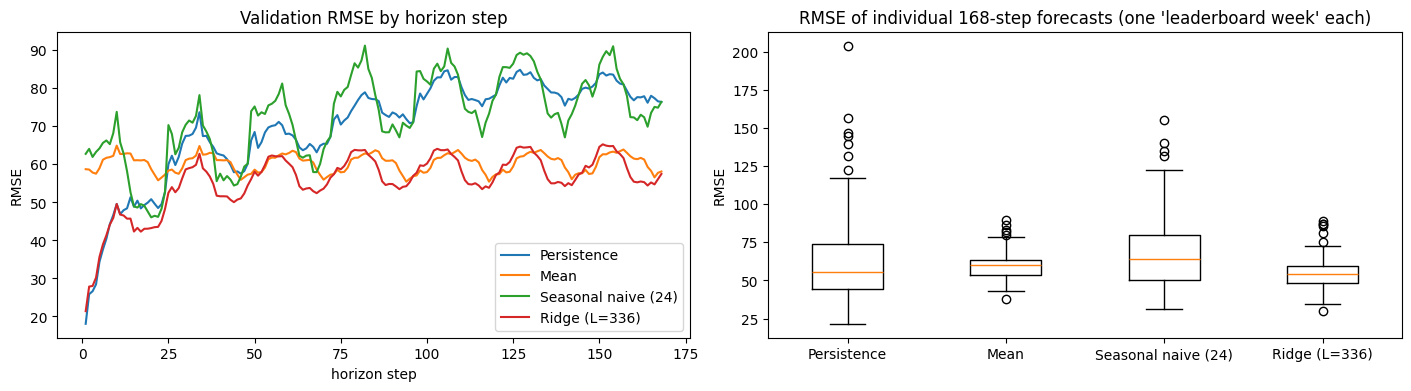

Persistence            single-week RMSE: p10 36 | median 55 | p90 106
Mean                   single-week RMSE: p10 47 | median 60 | p90 73
Seasonal naive (24)    single-week RMSE: p10 41 | median 64 | p90 103
Ridge (L=336)          single-week RMSE: p10 44 | median 54 | p90 67
validation mean 71.0 vs training mean 99.9


In [13]:
# Results table and figures

baseline_preds = {
    "Persistence": persistence(VAL_ORIGINS),
    "Mean": mean_forecast(VAL_ORIGINS),
    "Seasonal naive (24)": seasonal24(VAL_ORIGINS),
    "Ridge (L=336)": ridge_predict(W_ridge, VAL_ORIGINS),
}
table_b = pd.DataFrame([{"model": k, **metrics(p, Y_val)} for k, p in baseline_preds.items()]).round(2)
table_b.to_csv(RESULTS / "B_baselines_validation.csv", index=False)
display(table_b)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), layout="constrained")
steps = np.arange(1, H + 1)
for name, p in baseline_preds.items():
    ax[0].plot(steps, horizon_rmse(p, Y_val), label=name)
ax[0].set(title="Validation RMSE by horizon step", xlabel="horizon step", ylabel="RMSE"); ax[0].legend()
ax[1].boxplot([block_rmse(p, Y_val) for p in baseline_preds.values()], labels=list(baseline_preds))
ax[1].set(title="RMSE of individual 168-step forecasts (one 'leaderboard week' each)", ylabel="RMSE")
save(fig, "B2_baselines"); plt.show()

for name, p in baseline_preds.items():
    b = block_rmse(p, Y_val)
    print(f"{name:22s} single-week RMSE: p10 {np.percentile(b, 10):.0f} | "
          f"median {np.median(b):.0f} | p90 {np.percentile(b, 90):.0f}")
print(f"validation mean {Y_val.mean():.1f} vs training mean {train_mean:.1f}")

### Preprocessing

In [14]:
# Ways to scale

def ridge_eval(train_end, eval_origins, L=336, mode="global z", lam=0.1):
    tr = y[:train_end]
    m0, s0 = tr.mean(), tr.std()
    lm, ls = np.log1p(tr).mean(), np.log1p(tr).std()
    if mode == "global z":
        fwd = lambda V, C: (V - m0) / s0
        inv = lambda Z, C: Z * s0 + m0
    elif mode == "log1p + z":
        fwd = lambda V, C: (np.log1p(V) - lm) / ls
        inv = lambda Z, C: np.expm1(Z * ls + lm)
    elif mode == "window mean/std":
        wm = lambda C: C.mean(1, keepdims=True); ws = lambda C: C.std(1, keepdims=True) + 1.0
        fwd = lambda V, C: (V - wm(C)) / ws(C)
        inv = lambda Z, C: Z * ws(C) + wm(C)
    elif mode == "anchor last value":
        fwd = lambda V, C: (V - C[:, -1:]) / s0
        inv = lambda Z, C: Z * s0 + C[:, -1:]
    tro = make_origins(0, train_end, stride=4, context=L)
    Ctr = contexts(tro, L)
    W = ridge_fit(np.c_[fwd(Ctr, Ctr), np.ones(len(tro))], fwd(targets(tro), Ctr), lam)
    Ce = contexts(eval_origins, L)
    return np.clip(inv(np.c_[fwd(Ce, Ce), np.ones(len(Ce))] @ W, Ce), 0, None)

modes = ["global z", "log1p + z", "window mean/std", "anchor last value"]

# C1: scaling, checked across four consecutive 16-week periods (the last one is validation)
rows = []
for k in (3, 2, 1, 0):
    start = VAL_START - k * BLOCK
    eo = make_origins(start, start + BLOCK)
    Te = targets(eo)
    row = {"period": f"[{start}, {start + BLOCK})" + (" validation" if k == 0 else ""),
           "period mean": Te.mean()}
    for m in modes:
        row[m] = metrics(ridge_eval(start, eo, mode=m), Te)["RMSE"]
    rows.append(row)
table_c1 = pd.DataFrame(rows)
table_c1.loc[len(table_c1)] = {"period": "average", **table_c1[["period mean"] + modes].mean()}
table_c1 = table_c1.round(1); table_c1.to_csv(RESULTS / "C1_scaling_across_periods.csv", index=False)
display(table_c1)

# C2: context length (global z, validation)
table_c2 = pd.DataFrame([{"context L": L, **metrics(ridge_eval(VAL_START, VAL_ORIGINS, L=L), Y_val)}
                         for L in (96, 168, 336, 504, 720, 1008)]).round(2)
table_c2.to_csv(RESULTS / "C2_context_length.csv", index=False)
display(table_c2)

,period,period mean,global z,log1p + z,window mean/std,anchor last value
0,"[30216, 32904)",77.4,59.0,57.5,58.9,58.3
1,"[32904, 35592)",101.8,99.1,104.4,102.9,102.5
2,"[35592, 38280)",118.6,101.2,112.8,109.8,107.4
3,"[38280, 40968) validation",71.0,56.1,51.1,55.0,54.9
4,average,92.2,78.9,81.5,81.6,80.8


,context L,RMSE,MAE,sMAPE
0,96,56.79,47.91,67.29
1,168,56.53,47.65,67.14
2,336,56.08,47.17,66.82
3,504,55.81,46.82,66.44
4,720,55.25,46.38,66.22
5,1008,54.82,46.00,66.03


### Autoformer architecture

In [16]:
%%writefile autoformer.py

Overwriting autoformer.py


In [21]:
import importlib
import autoformer as af
importlib.reload(af)                     

x = torch.tensor([1., 2., 3., 10., 5.]).reshape(1, 5, 1)
_, trend = af.SeriesDecomposition(3)(x)
print("trend:", [round(v, 3) for v in trend.flatten().tolist()], "| expected [1.333, 2, 5, 6, 6.667]")
v = torch.tensor([10., 20., 30., 40.]).reshape(1, 1, 1, 4)
print("aggregate:", af.aggregate_delays(v, torch.tensor([[1, 3]]), torch.tensor([[.75, .25]])).flatten().tolist(),
      "| expected [35, 15, 25, 25]")

for c_cov in (0, 13):
    model = af.Autoformer(c_cov=c_cov)
    xb = torch.randn(4, 336, 1, requires_grad=True)
    cov_enc = torch.randn(4, 336, c_cov) if c_cov else None     
    cov_dec = torch.randn(4, 336, c_cov) if c_cov else None    
    out = model(xb, cov_enc, cov_dec)
    assert out.shape == (4, 168)
    out.square().mean().backward()
    unused = [n for n, p in model.named_parameters() if p.grad is None]
    assert xb.grad.abs().sum() > 0 and not unused, unused
    print(f"c_cov={c_cov}: output {tuple(out.shape)}, parameters {af.count_parameters(model):,}")

display(pd.DataFrame([{"d_model": d, "parameters": af.count_parameters(af.Autoformer(d_model=d, d_ff=2 * d))}
                      for d in (16, 32, 64)]))

trend: [1.333, 2.0, 5.0, 6.0, 6.667] | expected [1.333, 2, 5, 6, 6.667]
aggregate: [35.0, 15.0, 25.0, 25.0] | expected [35, 15, 25, 25]
c_cov=0: output (4, 168), parameters 21,313
c_cov=13: output (4, 168), parameters 22,145


,d_model,parameters
0,16,5537
1,32,21313
2,64,83585


### Training

In [22]:
import copy, time
import torch.nn.functional as F

L, LABEL = 336, 168
y_scaled = torch.tensor((y - mu) / sd, dtype=torch.float32, device=device)  # mu, sd: training stats from Part B
OFF_CTX = torch.arange(-L, 0, device=device)
OFF_TGT = torch.arange(0, H, device=device)

def batch_windows(origins):
    """origins: LongTensor on device -> context [B, L, 1], target [B, H] (both scaled)."""
    x = y_scaled[origins[:, None] + OFF_CTX].unsqueeze(-1)
    t = y_scaled[origins[:, None] + OFF_TGT]
    return x, t

TRAIN_O = torch.as_tensor(make_origins(0, VAL_START, stride=1, context=L), device=device)
VAL_O = torch.as_tensor(VAL_ORIGINS, device=device)
print(f"{len(TRAIN_O)} training windows | {len(VAL_O)} validation forecasts")

37777 training windows | 106 validation forecasts


In [23]:
@torch.no_grad()
def predict(model, origins, batch=1024):
    model.eval(); out = []
    for i in range(0, len(origins), batch):
        x, _ = batch_windows(origins[i:i + batch]); out.append(model(x))
    return np.clip(torch.cat(out).cpu().numpy() * sd + mu, 0, None)     # back to original units, >= 0

TREND_PARAMS = {"trend_last", "trend_mean", "trend_bias"}

def train_model(make_model, seed, max_epochs=10, lr=1e-3, trend_lr=3e-2, batch=128, patience=3, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_model().to(device)
    groups = [{"params": [p for n, p in model.named_parameters() if n not in TREND_PARAMS], "lr": lr},
              {"params": [p for n, p in model.named_parameters() if n in TREND_PARAMS],
               "lr": trend_lr, "weight_decay": 0.0}]
    opt = torch.optim.AdamW([g for g in groups if g["params"]], weight_decay=1e-4)
    gen = torch.Generator().manual_seed(seed)
    best, best_state, best_epoch, wait, history = np.inf, None, 0, 0, []
    t0 = time.time()
    for epoch in range(1, max_epochs + 1):
        model.train(); total = 0.0
        order = TRAIN_O[torch.randperm(len(TRAIN_O), generator=gen).to(device)]
        for i in range(0, len(order), batch):
            x, t = batch_windows(order[i:i + batch])
            loss = F.mse_loss(model(x), t)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            total += loss.item() * len(x)
        val = metrics(predict(model, VAL_O), Y_val)
        history.append({"epoch": epoch, "train MSE (scaled)": total / len(order), **val})
        if verbose:
            print(f"  epoch {epoch}: train {total / len(order):.3f} | val RMSE {val['RMSE']:.2f} "
                  f"MAE {val['MAE']:.2f} | {time.time() - t0:.0f}s")
        if val["RMSE"] < best:
            best, best_state, best_epoch, wait = val["RMSE"], copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    record = {"seed": seed, "best epoch": best_epoch, "epochs run (E)": epoch, "val RMSE": best,
              "parameters (P)": af.count_parameters(model), "seconds": time.time() - t0}
    return model, record, pd.DataFrame(history)

Autoformer (paper trend init)
  epoch 1: train 1.084 | val RMSE 57.29 MAE 45.73 | 12s
  epoch 2: train 1.047 | val RMSE 59.65 MAE 46.09 | 22s
  epoch 3: train 1.063 | val RMSE 57.50 MAE 44.12 | 31s
  epoch 4: train 1.049 | val RMSE 64.34 MAE 47.24 | 41s
Autoformer (learned trend init)
  epoch 1: train 0.947 | val RMSE 57.67 MAE 48.54 | 10s
  epoch 2: train 0.935 | val RMSE 58.40 MAE 49.25 | 20s
  epoch 3: train 0.931 | val RMSE 59.84 MAE 50.62 | 30s
  epoch 4: train 0.928 | val RMSE 56.80 MAE 47.48 | 40s
  epoch 5: train 0.925 | val RMSE 57.01 MAE 47.74 | 50s
  epoch 6: train 0.924 | val RMSE 55.61 MAE 46.13 | 61s
  epoch 7: train 0.924 | val RMSE 55.56 MAE 46.30 | 71s
  epoch 8: train 0.922 | val RMSE 57.83 MAE 48.72 | 81s
  epoch 9: train 0.921 | val RMSE 57.67 MAE 48.36 | 91s
  epoch 10: train 0.920 | val RMSE 57.59 MAE 48.44 | 101s


,model,RMSE,MAE,sMAPE,best epoch,E,P
0,Ridge (L=336),56.08,47.17,66.82,NaN,NaN,NaN
1,Autoformer (paper trend init),57.29,45.73,67.96,1.0,4.0,21313.0
2,Autoformer (learned trend init),55.56,46.30,66.16,7.0,10.0,21817.0


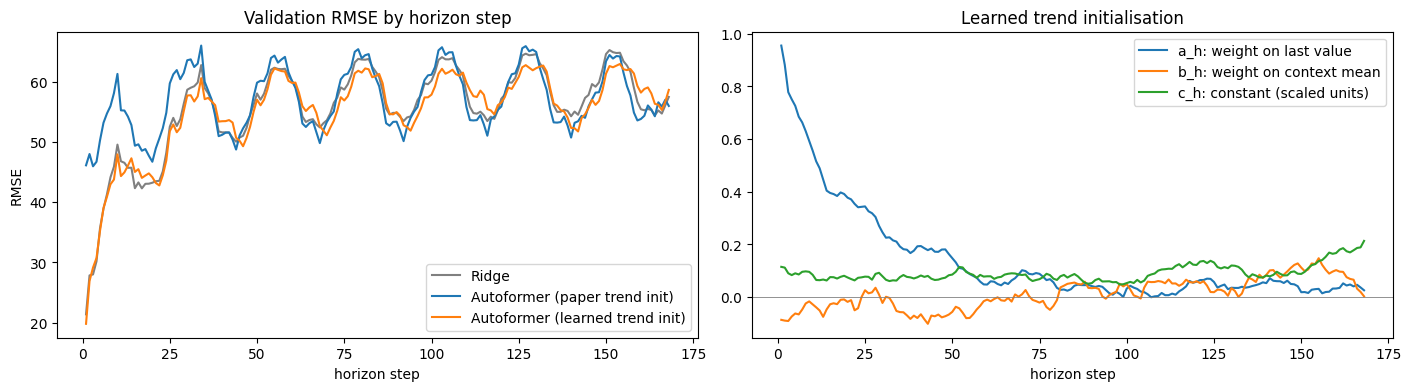

In [24]:
configs = {"Autoformer (paper trend init)": dict(trend_init="mean"),
           "Autoformer (learned trend init)": dict(trend_init="learned")}
runs = {}
for name, kwargs in configs.items():
    print(name)
    runs[name] = train_model(lambda: af.Autoformer(**kwargs), seed=0)

rows = [{"model": "Ridge (L=336)", **metrics(baseline_preds["Ridge (L=336)"], Y_val)}]
for name, (model, rec, _) in runs.items():
    rows.append({"model": name, **metrics(predict(model, VAL_O), Y_val),
                 "best epoch": rec["best epoch"], "E": rec["epochs run (E)"], "P": rec["parameters (P)"]})
table_f = pd.DataFrame(rows).round(2); table_f.to_csv(RESULTS / "F_first_autoformer.csv", index=False)
display(table_f)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), layout="constrained")
ax[0].plot(steps, horizon_rmse(baseline_preds["Ridge (L=336)"], Y_val), label="Ridge", c="gray")
for name, (model, _, _) in runs.items():
    ax[0].plot(steps, horizon_rmse(predict(model, VAL_O), Y_val), label=name)
ax[0].set(title="Validation RMSE by horizon step", xlabel="horizon step", ylabel="RMSE"); ax[0].legend()
learned = runs["Autoformer (learned trend init)"][0]
for p, label in ((learned.trend_last, "a_h: weight on last value"),
                 (learned.trend_mean, "b_h: weight on context mean"),
                 (learned.trend_bias, "c_h: constant (scaled units)")):
    ax[1].plot(steps, p.detach().cpu().numpy(), label=label)
ax[1].axhline(0, c="gray", lw=0.6)
ax[1].set(title="Learned trend initialisation", xlabel="horizon step"); ax[1].legend()
save(fig, "F_trend_init"); plt.show()

In [28]:
ext = pd.read_csv("/content/drive/MyDrive/q2/optional_external_data.csv")
cont = ["feature_A", "feature_B", "feature_C"]
counters = ["feature_D", "feature_E", "feature_F"]
cats = ["feature_G", "feature_H", "feature_I", "feature_J"]
tr = slice(0, VAL_START)                                 

def zscore(M):
    return (M - M[tr].mean(0)) / M[tr].std(0)

file_block = np.c_[zscore(ext[cont].to_numpy(float)),
                   zscore(np.log1p(ext[counters].to_numpy(float))),
                   ext[cats].to_numpy(float)]                          
t_all = np.arange(len(ext))                                        
phase_block = np.c_[np.sin(2 * np.pi * t_all / 24), np.cos(2 * np.pi * t_all / 24)]

COV_ALL = torch.tensor(np.c_[phase_block, file_block], dtype=torch.float32, device=device)
print("covariates:", tuple(COV_ALL.shape), "| cols 0-1 phase, cols 2-11 file")

COV_SETS = {"none": [], "phase": [0, 1], "file past": list(range(12)), "file past+future": list(range(12))}
OFF_DEC = torch.arange(-LABEL, H, device=device)                   

def batch_covariates(origins, mode):
    cols = COV_SETS[mode]
    if not cols:
        return None, None
    enc = COV_ALL[origins[:, None] + OFF_CTX][..., cols]            
    dec = COV_ALL[origins[:, None] + OFF_DEC][..., cols].clone()    
    if mode == "file past":
        dec[:, LABEL:, 2:] = 0.0                                     
    return enc, dec

covariates: (43824, 12) | cols 0-1 phase, cols 2-11 file


In [29]:
# Ridge evidence

def ridge_cov_eval(start, file_mode, L=336):
    """Ridge RMSE on the 16-week period starting at `start`, trained only on data before it.
    Note: covariate scaling uses the main training statistics for every period (features only)."""
    m0, s0 = y[:start].mean(), y[:start].std()
    def build(o):
        X = [(contexts(o, L) - m0) / s0]
        if file_mode != "none":
            X.append(np.stack([phase_block[i:i + H].ravel() for i in o]))
            X.append(np.stack([file_block[i - 24:i].ravel() for i in o]))
        if file_mode == "past+future":
            X.append(np.stack([file_block[i:i + H].ravel() for i in o]))
        X.append(np.ones((len(o), 1)))
        return np.concatenate(X, 1)
    tro = make_origins(0, start, stride=4, context=L)
    eo = make_origins(start, start + BLOCK)
    W = ridge_fit(build(tro), (targets(tro) - m0) / s0, 1.0 if file_mode == "past" else 0.1)
    return metrics(np.clip(build(eo) @ W * s0 + m0, 0, None), targets(eo))["RMSE"]

rows = []
for k in (3, 2, 1, 0):
    start = VAL_START - k * BLOCK
    rows.append({"period": f"[{start}, {start + BLOCK})" + (" validation" if k == 0 else ""),
                 **{f"ridge, {m}": ridge_cov_eval(start, m) for m in ("none", "past", "past+future")}})
table_e = pd.DataFrame(rows)
table_e.loc[len(table_e)] = {"period": "average", **table_e.iloc[:, 1:].mean()}
table_e = table_e.round(1); table_e.to_csv(RESULTS / "E_ridge_covariates_periods.csv", index=False)
display(table_e)

,period,"ridge, none","ridge, past","ridge, past+future"
0,"[30216, 32904)",59.0,57.9,47.1
1,"[32904, 35592)",99.1,98.0,68.4
2,"[35592, 38280)",101.2,99.1,70.9
3,"[38280, 40968) validation",56.1,54.0,45.4
4,average,78.9,77.3,58.0


In [34]:
def batch_inputs(origins, mode):
    x, t = batch_windows(origins)
    cov_enc, cov_dec = batch_covariates(origins, mode)
    return x, t, cov_enc, cov_dec

@torch.no_grad()
def predict(model, origins, mode="none", batch=1024):
    model.eval(); out = []
    for i in range(0, len(origins), batch):
        x, _, ce, cd = batch_inputs(origins[i:i + batch], mode)
        out.append(model(x, ce, cd))
    return np.clip(torch.cat(out).cpu().numpy() * sd + mu, 0, None)

def train_model(make_model, seed, mode="none", max_epochs=10, lr=1e-3, trend_lr=3e-2, batch=128,
                patience=3, lr_decay=0.5, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_model().to(device)
    groups = [{"params": [p for n, p in model.named_parameters() if n not in TREND_PARAMS], "lr": lr},
              {"params": [p for n, p in model.named_parameters() if n in TREND_PARAMS],
               "lr": trend_lr, "weight_decay": 0.0}]
    opt = torch.optim.AdamW([g for g in groups if g["params"]], weight_decay=1e-4)
    gen = torch.Generator().manual_seed(seed)
    best, best_state, best_epoch, wait, history = np.inf, None, 0, 0, []
    t0 = time.time()
    for epoch in range(1, max_epochs + 1):
        model.train(); total = 0.0
        order = TRAIN_O[torch.randperm(len(TRAIN_O), generator=gen).to(device)]
        for i in range(0, len(order), batch):
            x, t, ce, cd = batch_inputs(order[i:i + batch], mode)
            loss = F.mse_loss(model(x, ce, cd), t)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            total += loss.item() * len(x)
        val = metrics(predict(model, VAL_O, mode), Y_val)
        history.append({"epoch": epoch, "train MSE (scaled)": total / len(order), **val})
        for g in opt.param_groups:       
            g["lr"] *= lr_decay
        if verbose:
            print(f"  epoch {epoch}: train {total / len(order):.3f} | val RMSE {val['RMSE']:.2f} "
                  f"MAE {val['MAE']:.2f} | {time.time() - t0:.0f}s")
        if val["RMSE"] < best:
            best, best_state, best_epoch, wait = val["RMSE"], copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    record = {"seed": seed, "mode": mode, "best epoch": best_epoch, "epochs run (E)": epoch, "val RMSE": best,
              "parameters (P)": af.count_parameters(model), "seconds": time.time() - t0}
    return model, record, pd.DataFrame(history)

In [31]:
cov_runs = {}
for mode in ["none", "phase", "file past", "file past+future"]:
    c = len(COV_SETS[mode])
    print(f"{mode} (c_cov={c})")
    cov_runs[mode] = train_model(lambda: af.Autoformer(c_cov=c, trend_init="learned"), seed=0, mode=mode)

rows = []
for mode, (model, rec, _) in cov_runs.items():
    p = predict(model, VAL_O, mode); h = horizon_rmse(p, Y_val)
    rows.append({"variant": mode, **metrics(p, Y_val), "steps 1-24": h[:24].mean(), "steps 97-168": h[96:].mean(),
                 "best epoch": rec["best epoch"], "E": rec["epochs run (E)"], "P": rec["parameters (P)"]})
table_e4 = pd.DataFrame(rows).round(2); table_e4.to_csv(RESULTS / "E_autoformer_variants_seed0.csv", index=False)
display(table_e4)

none (c_cov=0)
  epoch 1: train 0.947 | val RMSE 57.55 MAE 48.40 | 10s
  epoch 2: train 0.935 | val RMSE 58.01 MAE 48.87 | 20s
  epoch 3: train 0.932 | val RMSE 60.74 MAE 51.39 | 31s
  epoch 4: train 0.928 | val RMSE 57.67 MAE 48.23 | 41s
phase (c_cov=2)
  epoch 1: train 0.927 | val RMSE 52.61 MAE 43.12 | 11s
  epoch 2: train 0.907 | val RMSE 52.99 MAE 43.53 | 21s
  epoch 3: train 0.895 | val RMSE 55.01 MAE 46.01 | 31s
  epoch 4: train 0.888 | val RMSE 54.69 MAE 45.09 | 42s
file past (c_cov=12)
  epoch 1: train 0.912 | val RMSE 50.93 MAE 40.81 | 10s
  epoch 2: train 0.845 | val RMSE 52.54 MAE 43.24 | 21s
  epoch 3: train 0.795 | val RMSE 54.33 MAE 45.32 | 31s
  epoch 4: train 0.758 | val RMSE 52.94 MAE 43.40 | 42s
file past+future (c_cov=12)
  epoch 1: train 0.604 | val RMSE 55.86 MAE 46.73 | 11s
  epoch 2: train 0.468 | val RMSE 51.26 MAE 41.35 | 21s
  epoch 3: train 0.420 | val RMSE 52.36 MAE 43.03 | 31s
  epoch 4: train 0.395 | val RMSE 53.58 MAE 44.12 | 42s
  epoch 5: train 0.380 |

,variant,RMSE,MAE,sMAPE,steps 1-24,steps 97-168,best epoch,E,P
0,none,57.55,48.40,67.53,41.81,60.19,1,4,21817
1,phase,52.61,43.12,63.75,39.84,54.76,1,4,21945
2,file past,50.93,40.81,62.01,39.42,52.32,1,4,22585
3,file past+future,48.49,39.31,59.09,43.17,50.51,6,9,22585


In [33]:
cov_trend_runs = {}
for name, kw in {"past+future": dict(), "past+future + cov_trend": dict(cov_trend=True)}.items():
    print(name)
    cov_trend_runs[name] = train_model(lambda: af.Autoformer(c_cov=12, trend_init="learned", **kw),
                                       seed=0, mode="file past+future")

rows = []
for name, (model, rec, _) in cov_trend_runs.items():
    p = predict(model, VAL_O, "file past+future"); h = horizon_rmse(p, Y_val)
    rows.append({"variant": name, **metrics(p, Y_val), "steps 1-24": h[:24].mean(),
                 "steps 97-168": h[96:].mean(), "best epoch": rec["best epoch"],
                 "E": rec["epochs run (E)"], "P": rec["parameters (P)"]})
table_e5 = pd.DataFrame(rows).round(2); table_e5.to_csv(RESULTS / "E_cov_trend_seed0.csv", index=False)
display(table_e5)

past+future
  epoch 1: train 0.604 | val RMSE 55.14 MAE 46.19 | 11s
  epoch 2: train 0.469 | val RMSE 53.27 MAE 43.43 | 21s
  epoch 3: train 0.420 | val RMSE 49.88 MAE 40.18 | 32s
  epoch 4: train 0.395 | val RMSE 52.74 MAE 43.53 | 43s
  epoch 5: train 0.378 | val RMSE 52.01 MAE 42.83 | 53s
  epoch 6: train 0.365 | val RMSE 47.25 MAE 37.80 | 63s
  epoch 7: train 0.354 | val RMSE 58.38 MAE 48.42 | 74s
  epoch 8: train 0.346 | val RMSE 50.71 MAE 41.25 | 84s
  epoch 9: train 0.339 | val RMSE 53.37 MAE 43.07 | 95s
past+future + cov_trend
  epoch 1: train 0.611 | val RMSE 48.79 MAE 39.18 | 11s
  epoch 2: train 0.458 | val RMSE 47.58 MAE 37.35 | 21s
  epoch 3: train 0.425 | val RMSE 55.87 MAE 44.74 | 32s
  epoch 4: train 0.404 | val RMSE 51.57 MAE 40.79 | 42s
  epoch 5: train 0.384 | val RMSE 52.41 MAE 42.39 | 53s


,variant,RMSE,MAE,sMAPE,steps 1-24,steps 97-168,best epoch,E,P
0,past+future,47.25,37.80,57.78,42.66,47.49,6,9,22585
1,past+future + cov_trend,47.58,37.35,59.38,42.01,47.99,2,5,22598


In [35]:
model, rec, hist = train_model(lambda: af.Autoformer(c_cov=12, trend_init="learned", cov_trend=True),
                               seed=0, mode="file past+future")
print(rec)

  epoch 1: train 0.610 | val RMSE 48.94 MAE 39.67 | 11s
  epoch 2: train 0.468 | val RMSE 48.68 MAE 38.84 | 22s
  epoch 3: train 0.441 | val RMSE 49.10 MAE 39.41 | 32s
  epoch 4: train 0.430 | val RMSE 50.69 MAE 41.06 | 43s
  epoch 5: train 0.425 | val RMSE 49.36 MAE 39.56 | 53s
{'seed': 0, 'mode': 'file past+future', 'best epoch': 2, 'epochs run (E)': 5, 'val RMSE': 48.68368847114413, 'parameters (P)': 22598, 'seconds': 53.13183784484863}


In [36]:
CONFIGS = {
    "paper trend, no covariates":      (dict(trend_init="mean"), "none"),
    "learned trend, no covariates":    (dict(trend_init="learned"), "none"),
    "learned trend, file past":        (dict(trend_init="learned"), "file past"),
    "learned trend, file past+future": (dict(trend_init="learned"), "file past+future"),
    "+ cov_trend, file past+future":   (dict(trend_init="learned", cov_trend=True), "file past+future"),
}
SEEDS = [0, 1, 2, 3, 4]

records, models_g = [], {}
for name, (kw, mode) in CONFIGS.items():
    c = len(COV_SETS[mode])
    for seed in SEEDS:
        model, rec, _ = train_model(lambda: af.Autoformer(c_cov=c, **kw), seed=seed, mode=mode, verbose=False)
        p = predict(model, VAL_O, mode); h = horizon_rmse(p, Y_val)
        records.append({"config": name, **rec, **metrics(p, Y_val),
                        "steps 1-24": h[:24].mean(), "steps 97-168": h[96:].mean()})
        models_g[(name, seed)] = model
        print(f"{name:34s} seed {seed} | val RMSE {rec['val RMSE']:.2f} | "
              f"best epoch {rec['best epoch']} | E {rec['epochs run (E)']} | {rec['seconds']:.0f}s")

runs_g = pd.DataFrame(records); runs_g.to_csv(RESULTS / "G_seed_runs.csv", index=False)

paper trend, no covariates         seed 0 | val RMSE 57.60 | best epoch 1 | E 4 | 41s
paper trend, no covariates         seed 1 | val RMSE 58.24 | best epoch 1 | E 4 | 41s
paper trend, no covariates         seed 2 | val RMSE 56.80 | best epoch 1 | E 4 | 41s
paper trend, no covariates         seed 3 | val RMSE 58.24 | best epoch 1 | E 4 | 41s
paper trend, no covariates         seed 4 | val RMSE 57.65 | best epoch 2 | E 5 | 51s
learned trend, no covariates       seed 0 | val RMSE 56.67 | best epoch 4 | E 7 | 72s
learned trend, no covariates       seed 1 | val RMSE 54.97 | best epoch 1 | E 4 | 41s
learned trend, no covariates       seed 2 | val RMSE 55.21 | best epoch 1 | E 4 | 41s
learned trend, no covariates       seed 3 | val RMSE 54.37 | best epoch 1 | E 4 | 41s
learned trend, no covariates       seed 4 | val RMSE 56.84 | best epoch 1 | E 4 | 41s
learned trend, file past           seed 0 | val RMSE 50.81 | best epoch 1 | E 4 | 42s
learned trend, file past           seed 1 | val RMSE 5

### Evaluation

In [37]:
HOLD_O = torch.as_tensor(HOLD_ORIGINS, device=device)
Y_hold = targets(HOLD_ORIGINS)
FINAL_NAME, FINAL_MODE = "+ cov_trend, file past+future", "file past+future"
FINAL_KW = dict(c_cov=12, trend_init="learned", cov_trend=True)
REFIT_EPOCHS = 2

def ridge_cov_forecast(train_end, eval_origins, file_mode, L=336):
    """Ridge trained on all windows before train_end; forecasts eval_origins."""
    m0, s0 = y[:train_end].mean(), y[:train_end].std()
    def build(o):
        X = [(contexts(o, L) - m0) / s0]
        if file_mode != "none":
            X.append(np.stack([phase_block[i:i + H].ravel() for i in o]))
            X.append(np.stack([file_block[i - 24:i].ravel() for i in o]))
        if file_mode == "past+future":
            X.append(np.stack([file_block[i:i + H].ravel() for i in o]))
        X.append(np.ones((len(o), 1)))
        return np.concatenate(X, 1)
    tro = make_origins(0, train_end, stride=4, context=L)
    W = ridge_fit(build(tro), (targets(tro) - m0) / s0, 1.0 if file_mode == "past" else 0.1)
    return np.clip(build(eval_origins) @ W * s0 + m0, 0, None)

def fit_fixed(make_model, seed, mode, train_end, epochs, lr=1e-3, trend_lr=3e-2, batch=128, lr_decay=0.5):
    """Train for a fixed number of epochs on every window whose target ends before train_end."""
    torch.manual_seed(seed); np.random.seed(seed)
    origins = torch.as_tensor(make_origins(0, train_end, stride=1, context=L), device=device)
    model = make_model().to(device)
    groups = [{"params": [p for n, p in model.named_parameters() if n not in TREND_PARAMS], "lr": lr},
              {"params": [p for n, p in model.named_parameters() if n in TREND_PARAMS],
               "lr": trend_lr, "weight_decay": 0.0}]
    opt = torch.optim.AdamW([g for g in groups if g["params"]], weight_decay=1e-4)
    gen = torch.Generator().manual_seed(seed)
    for _ in range(epochs):
        model.train()
        order = origins[torch.randperm(len(origins), generator=gen).to(device)]
        for i in range(0, len(order), batch):
            x, t, ce, cd = batch_inputs(order[i:i + batch], mode)
            loss = F.mse_loss(model(x, ce, cd), t)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        for g in opt.param_groups:
            g["lr"] *= lr_decay
    return model

rows = [
    {"model": "Persistence", **metrics(persistence(HOLD_ORIGINS), Y_hold)},
    {"model": "Mean (train)", **metrics(mean_forecast(HOLD_ORIGINS), Y_hold)},
    {"model": "Ridge, no covariates (train only)", **metrics(ridge_predict(W_ridge, HOLD_ORIGINS), Y_hold)},
    {"model": "Ridge + file past+future (train only)",
     **metrics(ridge_cov_forecast(VAL_START, HOLD_ORIGINS, "past+future"), Y_hold)},
    {"model": "Ridge + file past+future (train + val)",
     **metrics(ridge_cov_forecast(HOLDOUT_START, HOLD_ORIGINS, "past+future"), Y_hold)},
]
for label, get_model in [
    ("Autoformer final config (train only, early-stopped)", lambda s: models_g[(FINAL_NAME, s)]),
    (f"Autoformer final config (refit train + val, {REFIT_EPOCHS} epochs)",
     lambda s: fit_fixed(lambda: af.Autoformer(**FINAL_KW), s, FINAL_MODE, HOLDOUT_START, REFIT_EPOCHS)),
]:
    per_seed = pd.DataFrame([metrics(predict(get_model(s), HOLD_O, FINAL_MODE), Y_hold) for s in SEEDS])
    rows.append({"model": label, **per_seed.mean().to_dict(), "RMSE std (seeds)": per_seed.RMSE.std()})
    print(label, "| per-seed RMSE:", per_seed.RMSE.round(2).tolist())

table_h1 = pd.DataFrame(rows).round(2); table_h1.to_csv(RESULTS / "H1_holdout.csv", index=False)
display(table_h1)

Autoformer final config (train only, early-stopped) | per-seed RMSE: [67.08, 66.95, 71.34, 70.15, 67.95]
Autoformer final config (refit train + val, 2 epochs) | per-seed RMSE: [68.96, 70.34, 71.99, 69.54, 68.5]


,model,RMSE,MAE,sMAPE,RMSE std (seeds)
0,Persistence,146.86,105.09,93.84,NaN
1,Mean (train),102.77,79.03,84.92,NaN
2,"Ridge, no covariates (train only)",99.74,75.80,81.77,NaN
3,Ridge + file past+future (train only),68.03,51.29,70.82,NaN
4,Ridge + file past+future (train + val),67.92,50.75,70.42,NaN
5,"Autoformer final config (train only, early-sto...",68.69,49.73,69.25,1.96
6,"Autoformer final config (refit train + val, 2 ...",69.87,51.70,69.93,1.37


P = 22,598 | E = 5 | forecast range 0.0-183.9, mean 91.7 | corr with ridge reference 0.88


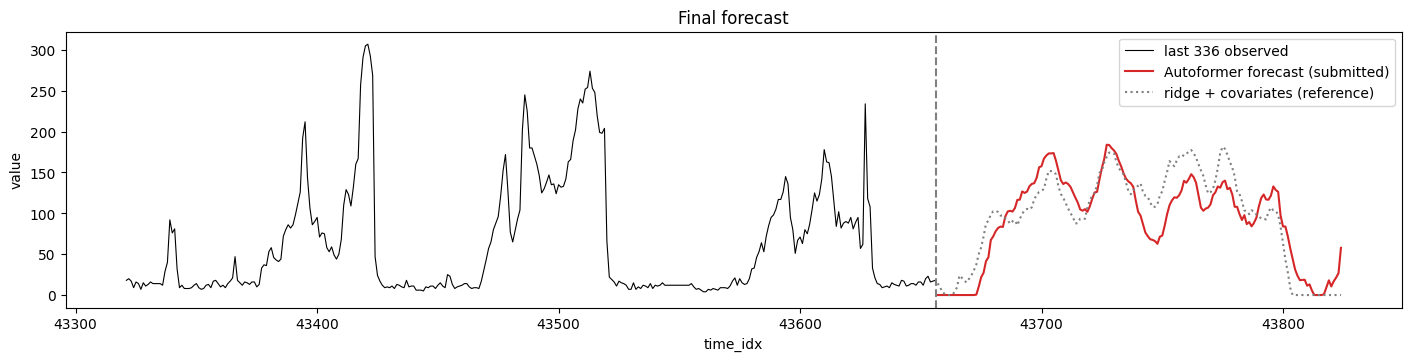

0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.48, 10.24, 21.85, 27.26, 41.41, 46.18, 67.34, 71.77, 78.05, 82.09, 83.76, 83.36, 96.12, 102.29, 103.06 ...


In [42]:
USE_REFIT = False
FINAL_SEED = 0

if USE_REFIT:
    final_model = fit_fixed(lambda: af.Autoformer(**FINAL_KW), FINAL_SEED, FINAL_MODE, N, REFIT_EPOCHS)
    early_stopped_E = runs_g.query("config == @FINAL_NAME and seed == @FINAL_SEED")["epochs run (E)"].item()
    E_DECLARED = early_stopped_E + REFIT_EPOCHS       
else:
    final_model = models_g[(FINAL_NAME, FINAL_SEED)]
    E_DECLARED = runs_g.query("config == @FINAL_NAME and seed == @FINAL_SEED")["epochs run (E)"].item()
P_DECLARED = af.count_parameters(final_model)

@torch.no_grad()
def forecast_final(model, mode):
    model.eval()
    o = torch.tensor([N], device=device)                        
    x = y_scaled[o[:, None] + OFF_CTX].unsqueeze(-1)           
    ce, cd = batch_covariates(o, mode)                           
    return np.clip(model(x, ce, cd)[0].cpu().numpy() * sd + mu, 0, None)

fc = forecast_final(final_model, FINAL_MODE)
ridge_ref = ridge_cov_forecast(N, np.array([N]), "past+future")[0] 

assert len(fc) == 168 and np.isfinite(fc).all() and (fc >= 0).all()
assert test.time_idx.tolist() == list(range(43657, 43825))
print(f"P = {P_DECLARED:,} | E = {E_DECLARED} | forecast range {fc.min():.1f}-{fc.max():.1f}, "
      f"mean {fc.mean():.1f} | corr with ridge reference {np.corrcoef(fc, ridge_ref)[0, 1]:.2f}")

submission = pd.DataFrame({"time_idx": test.time_idx, "value": fc})
submission.to_csv(RESULTS / "submission.csv", index=False)
paste = ", ".join(f"{v:.2f}" for v in fc)
(RESULTS / "submission_paste.txt").write_text(paste)

fig, ax = plt.subplots(figsize=(14, 3.5), layout="constrained")
ax.plot(np.arange(N - 336, N) + 1, y[-336:], c="k", lw=0.8, label="last 336 observed")
ax.plot(test.time_idx, fc, c="tab:red", label="Autoformer forecast (submitted)")
ax.plot(test.time_idx, ridge_ref, c="gray", ls=":", label="ridge + covariates (reference)")
ax.axvline(N + 0.5, c="gray", ls="--"); ax.set(title="Final forecast", xlabel="time_idx", ylabel="value"); ax.legend()
save(fig, "H2_final_forecast"); plt.show()
print(paste[:200], "...")

P = 22,598 | E = 5 | forecast range 0.0-210.2, mean 101.7 | corr with ridge reference 0.85


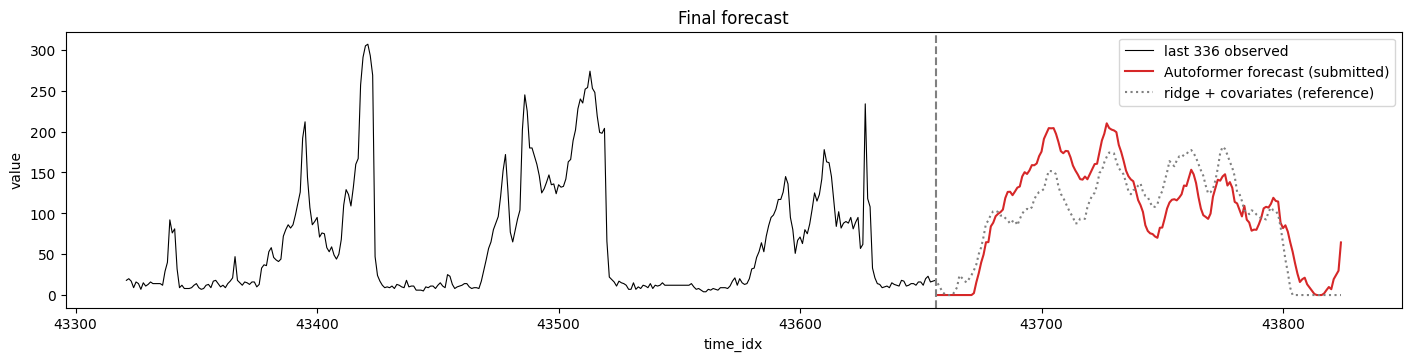

0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 2.35, 15.58, 26.63, 39.72, 49.59, 64.62, 64.76, 83.99, 88.54, 96.51, 99.39, 101.49, 104.58, 118.75, 126.20, 12 ...


In [28]:
USE_REFIT = False
FINAL_SEED = 0

if USE_REFIT:
    final_model = fit_fixed(lambda: af.Autoformer(**FINAL_KW), FINAL_SEED, FINAL_MODE, N, REFIT_EPOCHS)
    early_stopped_E = runs_g.query("config == @FINAL_NAME and seed == @FINAL_SEED")["epochs run (E)"].item()
    E_DECLARED = early_stopped_E + REFIT_EPOCHS       
else:
    final_model = models_g[(FINAL_NAME, FINAL_SEED)]
    E_DECLARED = runs_g.query("config == @FINAL_NAME and seed == @FINAL_SEED")["epochs run (E)"].item()
P_DECLARED = af.count_parameters(final_model)

@torch.no_grad()
def forecast_final(model, mode):
    model.eval()
    o = torch.tensor([N], device=device)                        
    x = y_scaled[o[:, None] + OFF_CTX].unsqueeze(-1)           
    ce, cd = batch_covariates(o, mode)                           
    return np.clip(model(x, ce, cd)[0].cpu().numpy() * sd + mu, 0, None)

fc = forecast_final(final_model, FINAL_MODE)
ridge_ref = ridge_cov_forecast(N, np.array([N]), "past+future")[0] 

assert len(fc) == 168 and np.isfinite(fc).all() and (fc >= 0).all()
assert test.time_idx.tolist() == list(range(43657, 43825))
print(f"P = {P_DECLARED:,} | E = {E_DECLARED} | forecast range {fc.min():.1f}-{fc.max():.1f}, "
      f"mean {fc.mean():.1f} | corr with ridge reference {np.corrcoef(fc, ridge_ref)[0, 1]:.2f}")

submission = pd.DataFrame({"time_idx": test.time_idx, "value": fc})
submission.to_csv(RESULTS / "submission.csv", index=False)
paste = ", ".join(f"{v:.2f}" for v in fc)
(RESULTS / "submission_paste.txt").write_text(paste)

fig, ax = plt.subplots(figsize=(14, 3.5), layout="constrained")
ax.plot(np.arange(N - 336, N) + 1, y[-336:], c="k", lw=0.8, label="last 336 observed")
ax.plot(test.time_idx, fc, c="tab:red", label="Autoformer forecast (submitted)")
ax.plot(test.time_idx, ridge_ref, c="gray", ls=":", label="ridge + covariates (reference)")
ax.axvline(N + 0.5, c="gray", ls="--"); ax.set(title="Final forecast", xlabel="time_idx", ylabel="value"); ax.legend()
save(fig, "H2_final_forecast"); plt.show()
print(paste[:200], "...")

epochs per seed: [[0, 5], [1, 5], [2, 5], [3, 4], [4, 4]]
P = 112,990 | E = 23 | range 0.0-198.1, mean 97.8 | corr with ridge 0.86 | corr with submission 1 0.99


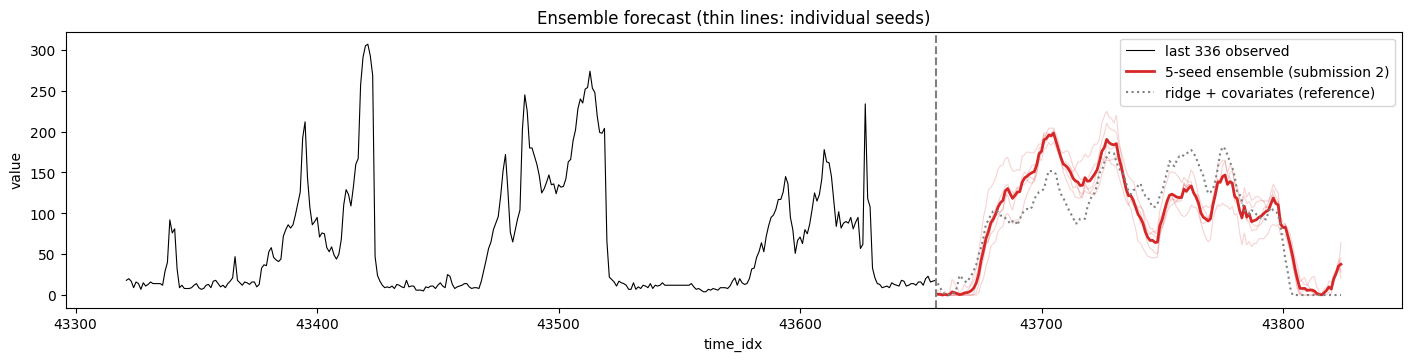

168 True


In [30]:
ens_models = [models_g[(FINAL_NAME, s)] for s in SEEDS]
P_ENS = sum(af.count_parameters(m) for m in ens_models)
E_ENS = int(runs_g.query("config == @FINAL_NAME")["epochs run (E)"].sum())
print("epochs per seed:", runs_g.query("config == @FINAL_NAME")[["seed", "epochs run (E)"]].values.tolist())

fc_ens = np.mean([forecast_final(m, FINAL_MODE) for m in ens_models], axis=0)

assert len(fc_ens) == 168 and np.isfinite(fc_ens).all() and (fc_ens >= 0).all()
print(f"P = {P_ENS:,} | E = {E_ENS} | range {fc_ens.min():.1f}-{fc_ens.max():.1f}, mean {fc_ens.mean():.1f} | "
      f"corr with ridge {np.corrcoef(fc_ens, ridge_ref)[0, 1]:.2f} | corr with submission 1 {np.corrcoef(fc_ens, fc)[0, 1]:.2f}")

pd.DataFrame({"time_idx": test.time_idx, "value": fc_ens}).to_csv(RESULTS / "submission2_ensemble.csv", index=False)
paste2 = ", ".join(f"{v:.2f}" for v in fc_ens)
(RESULTS / "submission2_paste.txt").write_text(paste2)

fig, ax = plt.subplots(figsize=(14, 3.5), layout="constrained")
ax.plot(np.arange(N - 336, N) + 1, y[-336:], c="k", lw=0.8, label="last 336 observed")
for m in ens_models:
    ax.plot(test.time_idx, forecast_final(m, FINAL_MODE), c="tab:red", alpha=0.2, lw=0.8)
ax.plot(test.time_idx, fc_ens, c="tab:red", lw=2, label="5-seed ensemble (submission 2)")
ax.plot(test.time_idx, ridge_ref, c="gray", ls=":", label="ridge + covariates (reference)")
ax.axvline(N + 0.5, c="gray", ls="--")
ax.set(title="Ensemble forecast (thin lines: individual seeds)", xlabel="time_idx", ylabel="value"); ax.legend()
save(fig, "H4_ensemble_forecast"); plt.show()

vals = [float(v) for v in (RESULTS / "submission2_paste.txt").read_text().split(",")]
print(len(vals), np.allclose(vals, fc_ens, atol=0.01))

In [31]:
EXTRA_SEEDS = [5, 6, 7, 8, 9]
kw, mode = CONFIGS[FINAL_NAME]
extra_records = []
for seed in EXTRA_SEEDS:
    model, rec, _ = train_model(lambda: af.Autoformer(c_cov=12, **kw), seed=seed, mode=mode, verbose=False)
    models_g[(FINAL_NAME, seed)] = model
    extra_records.append({"config": FINAL_NAME, **rec})
    print(f"seed {seed} | val RMSE {rec['val RMSE']:.2f} | best epoch {rec['best epoch']} | E {rec['epochs run (E)']}")
runs_extra = pd.DataFrame(extra_records); runs_extra.to_csv(RESULTS / "H5_extra_seed_runs.csv", index=False)

def ensemble_predict(seeds, origins):
    return np.mean([predict(models_g[(FINAL_NAME, s)], origins, FINAL_MODE) for s in seeds], axis=0)

SEEDS_10 = SEEDS + EXTRA_SEEDS
rows = []
for split, O, Y in (("validation", VAL_O, Y_val), ("holdout", HOLD_O, Y_hold)):
    rows.append({"split": split, "model": "5-seed ensemble (submission 2)", **metrics(ensemble_predict(SEEDS, O), Y)})
    rows.append({"split": split, "model": "10-seed ensemble", **metrics(ensemble_predict(SEEDS_10, O), Y)})
table_h5 = pd.DataFrame(rows).round(2); table_h5.to_csv(RESULTS / "H5_ensemble_10.csv", index=False)
display(table_h5)

h = table_h5.set_index(["split", "model"])["RMSE"]
hold_gain = h["holdout", "5-seed ensemble (submission 2)"] - h["holdout", "10-seed ensemble"]
val_gain = h["validation", "5-seed ensemble (submission 2)"] - h["validation", "10-seed ensemble"]
print(f"holdout gain {hold_gain:.2f} | validation gain {val_gain:.2f} -> "
      + ("SUBMIT the 10-seed ensemble" if hold_gain >= 0.3 and val_gain >= 0 else "DO NOT submit; submission 2 stays final"))

seed 5 | val RMSE 43.90 | best epoch 2 | E 5
seed 6 | val RMSE 47.93 | best epoch 1 | E 4
seed 7 | val RMSE 47.57 | best epoch 5 | E 8
seed 8 | val RMSE 46.34 | best epoch 1 | E 4
seed 9 | val RMSE 45.69 | best epoch 3 | E 6


,split,model,RMSE,MAE,sMAPE
0,validation,5-seed ensemble (submission 2),43.33,34.65,53.90
1,validation,10-seed ensemble,43.42,34.93,54.13
2,holdout,5-seed ensemble (submission 2),66.83,47.13,61.82
3,holdout,10-seed ensemble,65.75,46.17,60.67


holdout gain 1.08 | validation gain -0.09 -> DO NOT submit; submission 2 stays final


In [32]:
ens10 = [models_g[(FINAL_NAME, s)] for s in SEEDS_10]
P_10 = sum(af.count_parameters(m) for m in ens10)
E_10 = int(runs_g.query("config == @FINAL_NAME")["epochs run (E)"].sum() + runs_extra["epochs run (E)"].sum())

fc_10 = np.mean([forecast_final(m, FINAL_MODE) for m in ens10], axis=0)
assert len(fc_10) == 168 and np.isfinite(fc_10).all() and (fc_10 >= 0).all()
print(f"P = {P_10:,} | E = {E_10} | mean {fc_10.mean():.1f} | corr with submission 2 {np.corrcoef(fc_10, fc_ens)[0, 1]:.3f}")

pd.DataFrame({"time_idx": test.time_idx, "value": fc_10}).to_csv(RESULTS / "submission3_ensemble10.csv", index=False)
(RESULTS / "submission3_paste.txt").write_text(", ".join(f"{v:.2f}" for v in fc_10))
vals = [float(v) for v in (RESULTS / "submission3_paste.txt").read_text().split(",")]
print(len(vals), np.allclose(vals, fc_10, atol=0.01))

P = 225,980 | E = 50 | mean 98.1 | corr with submission 2 0.996
168 True
